# EDA — Predicción de Popularidad de Canciones
## Spotify Tracks Dataset | MLY1101 Machine Learning | EP1

**Pregunta de investigación:** ¿qué explica que una canción sea popular en Spotify, y hasta qué punto los atributos de audio por sí solos permiten predecirlo?

**Advertencia metodológica:** un primer acercamiento simple (correlación de Pearson) sugiere que los atributos de audio tienen relación casi nula con `popularity`. En vez de concluir ahí, este EDA investiga sistemáticamente múltiples variables y técnicas antes de aceptar o descartar esa conclusión.

Este notebook es exploratorio: no transforma el dataset de forma permanente. Las decisiones de preparación de datos que surjan aquí se ejecutan en `02_Preparacion.ipynb`.

In [35]:
SPOTIFY_GREEN = '#1DB954'
SPOTIFY_BLACK = '#191414'
SPOTIFY_LIGHT = '#1ED760'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import skew, kurtosis, kruskal, mannwhitneyu

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.max_columns', None)

print("Entorno configurado correctamente.")

Entorno configurado correctamente.


In [ ]:
df = pd.read_csv('../data/raw/dataset.csv')

print(f"Dimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")
df.head()

Dimensiones: 114000 filas × 21 columnas


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### Diccionario de variables

| Columna | Tipo | Rol | Descripción |
|---|---|---|---|
| `track_id` | str | Identificador | ID único de Spotify (puede repetirse entre álbumes) |
| `artists` | str | Categórica alta cardinalidad | Artista(s) de la canción |
| `album_name` | str | Categórica alta cardinalidad | Álbum en que aparece |
| `track_name` | str | Texto | Nombre de la canción |
| `popularity` | int | **Variable objetivo** | 0–100, calculado por el algoritmo de Spotify |
| `duration_ms` | int | Numérica | Duración en milisegundos |
| `explicit` | bool | Categórica binaria | Contenido explícito |
| `danceability` ... `tempo` | float | Numéricas continuas (audio) | Atributos de audio, mayoría en escala 0–1 |
| `key` | int | Categórica | Tonalidad (0–11, -1 = no detectada) |
| `mode` | int | Categórica binaria | Mayor (1) / menor (0) |
| `time_signature` | int | Categórica | Compás estimado (3–7) |
| `track_genre` | str | Categórica alta cardinalidad | Género musical (114 valores) |

### Cierre — Fase 0

Entorno listo, dataset cargado, variables clasificadas por rol. Aún no hay ningún análisis ni conclusión — eso empieza en la **Fase 1: Anatomía del dataset**.

## Fase 1 — Anatomía del dataset

Antes de calcular cualquier estadística, clasificamos cada variable según su naturaleza. Esto determina qué operaciones tienen sentido para cada una (¿tiene sentido promediar esto? ¿correlacionar esto?).

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [12]:
roles = {
    'Identificador': ['track_id'],
    'Objetivo': ['popularity'],
    'Categórica alta cardinalidad': ['artists', 'album_name', 'track_name', 'track_genre'],
    'Categórica binaria': ['explicit', 'mode'],
    'Categórica ordinal/discreta': ['key', 'time_signature'],
    'Numérica (audio, escala 0-1)': ['danceability', 'energy', 'speechiness',
                                       'acousticness', 'instrumentalness', 'liveness', 'valence'],
    'Numérica (otra escala)': ['duration_ms', 'loudness', 'tempo'],
}

for rol, cols in roles.items():
    print(f"\n{rol}:")
    for c in cols:
        print(f"  - {c} ({df[c].dtype})")


Identificador:
  - track_id (str)

Objetivo:
  - popularity (int64)

Categórica alta cardinalidad:
  - artists (str)
  - album_name (str)
  - track_name (str)
  - track_genre (str)

Categórica binaria:
  - explicit (bool)
  - mode (int64)

Categórica ordinal/discreta:
  - key (int64)
  - time_signature (int64)

Numérica (audio, escala 0-1):
  - danceability (float64)
  - energy (float64)
  - speechiness (float64)
  - acousticness (float64)
  - instrumentalness (float64)
  - liveness (float64)
  - valence (float64)

Numérica (otra escala):
  - duration_ms (int64)
  - loudness (float64)
  - tempo (float64)


In [13]:
cat_cols = roles['Categórica alta cardinalidad'] + roles['Categórica binaria'] + roles['Categórica ordinal/discreta']

cardinalidad = pd.DataFrame({
    'columna': cat_cols,
    'valores_unicos': [df[c].nunique() for c in cat_cols]
}).sort_values('valores_unicos', ascending=False)

cardinalidad

,columna,valores_unicos
2,track_name,73608
1,album_name,46589
0,artists,31437
3,track_genre,114
6,key,12
7,time_signature,5
5,mode,2
4,explicit,2


In [14]:
num_cols = roles['Numérica (audio, escala 0-1)'] + roles['Numérica (otra escala)'] + ['popularity']
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.00000,0.000042,0.0490,1.000
liveness,114000.0,0.213553,0.190378,0.000,0.09800,0.132000,0.2730,1.000
valence,114000.0,0.474068,0.259261,0.000,0.26000,0.464000,0.6830,0.995
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
tempo,114000.0,122.147837,29.978197,0.000,99.21875,122.017000,140.0710,243.372


### Cierre — Fase 1

Quedan clasificadas todas las variables por rol y naturaleza, y se registró la cardinalidad de las categóricas y el resumen estadístico de las numéricas.

## Fase 2 — Auditoría de calidad y estructura

La Fase 1 dejó dos alertas (`duration_ms` y `tempo` en 0) y una variable con patrón de repetición (`track_id`) a investigar. Esta fase cuantifica esos hallazgos antes de decidir qué hacer con ellos.

In [15]:
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]
print("Columnas con valores nulos:")
print(nulos if len(nulos) > 0 else "Ninguna")

Columnas con valores nulos:
artists       1
album_name    1
track_name    1
dtype: int64


In [16]:
print(f"Canciones con duration_ms = 0: {(df['duration_ms'] == 0).sum()}")
print(f"Canciones con tempo = 0: {(df['tempo'] == 0).sum()}")
print(f"Canciones con AMBOS en 0: {((df['duration_ms'] == 0) & (df['tempo'] == 0)).sum()}")

df[(df['duration_ms'] == 0) | (df['tempo'] == 0)][['track_name', 'artists', 'duration_ms', 'tempo', 'popularity']].head(10)

Canciones con duration_ms = 0: 1
Canciones con tempo = 0: 157
Canciones con AMBOS en 0: 0


,track_name,artists,duration_ms,tempo,popularity
4131,The Departure,Max Richter;Lang Lang,151506,0.0,64
4379,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,73266,0.0,55
4664,Ferme Les Yeux,Sylvain Chauveau,68493,0.0,53
45670,Campomoro,Little Symphony,148711,0.0,22
45720,Ritornello,Little Symphony,102000,0.0,23
45729,Amager,Little Symphony,133624,0.0,22
45773,Ionian,Little Symphony,93125,0.0,22
59221,Yes! No! I Mean Yes! No I Don't!,Leila Bela,38333,0.0,0
59310,The Exorsism Begins...,Leila Bela,8586,0.0,0
59473,Leaving Her Quantum Journey Behind...,Leila Bela,50186,0.0,0


In [17]:
conteo_repeticion = df['track_id'].value_counts()

print(f"track_id únicos: {conteo_repeticion.shape[0]}")
print(f"track_id que aparecen 1 sola vez: {(conteo_repeticion == 1).sum()}")
print(f"track_id que aparecen más de 1 vez: {(conteo_repeticion > 1).sum()}")
print(f"\nDistribución de veces repetido:")
print(conteo_repeticion.value_counts().sort_index().head(15))
print(f"\nMáximo de repeticiones de un mismo track_id: {conteo_repeticion.max()}")

track_id únicos: 89741
track_id que aparecen 1 sola vez: 73100
track_id que aparecen más de 1 vez: 16641

Distribución de veces repetido:
count
1    73100
2    11712
3     2984
4     1372
5      431
6      117
7       22
8        2
9        1
Name: count, dtype: int64

Máximo de repeticiones de un mismo track_id: 9


In [18]:
duplicados_exactos = df.duplicated().sum()
print(f"Filas completamente duplicadas (todas las columnas iguales): {duplicados_exactos}")

Filas completamente duplicadas (todas las columnas iguales): 0


In [19]:
duplicados_ocultos = df.duplicated(subset=['track_name', 'artists'], keep=False)
n_duplicados_ocultos = duplicados_ocultos.sum()
n_track_id_en_duplicados = df[duplicados_ocultos]['track_id'].nunique()

print(f"Filas que comparten track_name + artists: {n_duplicados_ocultos}")
print(f"track_id distintos involucrados en esos casos: {n_track_id_en_duplicados}")

# Ejemplo concreto
ejemplo = df[duplicados_ocultos].sort_values(['track_name', 'artists']).head(10)
ejemplo[['track_id', 'track_name', 'artists', 'album_name', 'popularity']]

Filas que comparten track_name + artists: 49157
track_id distintos involucrados en esos casos: 24898


,track_id,track_name,artists,album_name,popularity
93397,3KKk48f33mlB56F5L5nbJk,"""Don Carlos"" Roderigo'S Death Aria",Nikolay Kopylov,Popular Opera Arias,0
93440,3KKk48f33mlB56F5L5nbJk,"""Don Carlos"" Roderigo'S Death Aria",Nikolay Kopylov,Popular Opera Arias,0
16385,4yfFraZrNnh2zJTok5fzq7,"""Hark! The Herald Angels Sing""",Felix Mendelssohn;Christopher Herrick;Simon Pr...,Klassische Weihnachtsmusik,0
39446,4yfFraZrNnh2zJTok5fzq7,"""Hark! The Herald Angels Sing""",Felix Mendelssohn;Christopher Herrick;Simon Pr...,Klassische Weihnachtsmusik,0
111315,1Ffxfl1vuEDc0xBVPIQ50s,"""Was He Slow?"" - Music From The Motion Picture...",Kid Koala,"""Was He Slow?"" (Music From The Motion Picture ...",37
111402,03XMXPAE2Yx6HeqCpAPL5o,"""Was He Slow?"" - Music From The Motion Picture...",Kid Koala,Baby Driver (Music from the Motion Picture),25
4152,2Bc4llhjJBW77I552RgA3L,#3,Aphex Twin,Selected Ambient Works Volume II,64
32514,2Bc4llhjJBW77I552RgA3L,#3,Aphex Twin,Selected Ambient Works Volume II,64
61045,7axpJkZcb36Wgjy0SxuEai,#おふしょるにっと,≠ME,チョコレートメランコリー<Special Edition>,33
63939,7axpJkZcb36Wgjy0SxuEai,#おふしょるにっと,≠ME,チョコレートメランコリー<Special Edition>,33


In [20]:
audio_cols = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
              'instrumentalness', 'liveness', 'valence', 'tempo']

track_ids_repetidos = df['track_id'].value_counts()
track_ids_repetidos = track_ids_repetidos[track_ids_repetidos > 1].index

std_por_track = df[df['track_id'].isin(track_ids_repetidos)].groupby('track_id')[audio_cols].std()

print("¿Los atributos de audio varían entre filas del mismo track_id repetido?")
print(std_por_track.describe().loc[['mean', 'max']])

print(f"\ntrack_id repetidos con AL MENOS una variable de audio distinta entre filas: "
      f"{(std_por_track.sum(axis=1) > 0).sum()} de {len(std_por_track)}")

¿Los atributos de audio varían entre filas del mismo track_id repetido?
      danceability  energy  loudness  speechiness  acousticness  \
mean           0.0     0.0       0.0          0.0           0.0   
max            0.0     0.0       0.0          0.0           0.0   

      instrumentalness  liveness  valence  tempo  
mean               0.0       0.0      0.0    0.0  
max                0.0       0.0      0.0    0.0  

track_id repetidos con AL MENOS una variable de audio distinta entre filas: 0 de 16641


In [21]:
rangos_0_1 = ['danceability', 'energy', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence']

for col in rangos_0_1:
    fuera_rango = ((df[col] < 0) | (df[col] > 1)).sum()
    if fuera_rango > 0:
        print(f"{col}: {fuera_rango} valores fuera de [0,1]")

print(f"key fuera de [-1,11]: {((df['key'] < -1) | (df['key'] > 11)).sum()}")
print(f"mode con valores distintos de {{0,1}}: {(~df['mode'].isin([0,1])).sum()}")
print(f"time_signature fuera de [3,7]: {((df['time_signature'] < 3) | (df['time_signature'] > 7)).sum()}")
print(f"explicit con valores distintos de {{True,False}}: {(~df['explicit'].isin([True, False])).sum()}")
print("\nSi no se imprimió ninguna alerta arriba (salvo estas últimas 4 líneas), todos los rangos están dentro de lo esperado.")

key fuera de [-1,11]: 0
mode con valores distintos de {0,1}: 0
time_signature fuera de [3,7]: 1136
explicit con valores distintos de {True,False}: 0

Si no se imprimió ninguna alerta arriba (salvo estas últimas 4 líneas), todos los rangos están dentro de lo esperado.


In [22]:
ts_raros = df[(df['time_signature'] < 3) | (df['time_signature'] > 7)]
print(ts_raros['time_signature'].value_counts().sort_index())
print(f"\nTotal: {len(ts_raros)} filas ({len(ts_raros)/len(df)*100:.2f}% del dataset)")

time_signature
0    163
1    973
Name: count, dtype: int64

Total: 1136 filas (1.00% del dataset)


### Cierre — Fase 2

**Calidad de datos:**
- 1 fila con nulos triples (artists, album_name, track_name).
- 1 canción con duration_ms = 0.
- 157 canciones con tempo = 0 y 1.136 con time_signature fuera de rango válido (0 o 1) — ambos casos interpretados como fallas de detección del algoritmo de Spotify ante ausencia de pulso rítmico claro (música ambient/clásica/instrumental), no como valores reales. Se tratan como dato faltante, no como cero real.
- 0 filas completamente duplicadas.

**Estructura de repetición:**
- Por `track_id`: 81% de canciones únicas, resto repetido mayoritariamente 2 veces (máximo 9).
- Los atributos de audio son idénticos entre filas de un mismo `track_id` repetido (std = 0) — es el mismo audio, sin inconsistencias.
- Por `track_name` + `artists`: 49.157 filas comparten esta combinación, involucrando 24.898 `track_id` distintos — más que los detectados solo por `track_id`. Esto indica que la misma canción publicada en distintos álbumes puede recibir `track_id` diferentes, con valores de `popularity` distintos entre versiones. La definición de "repetición" que se use en la Fase 4 debe considerar esta ambigüedad.

## Fase 3 — El target bajo la lupa

Antes de buscar relaciones con otras variables, entendemos a fondo cómo se comporta `popularity` por sí sola.

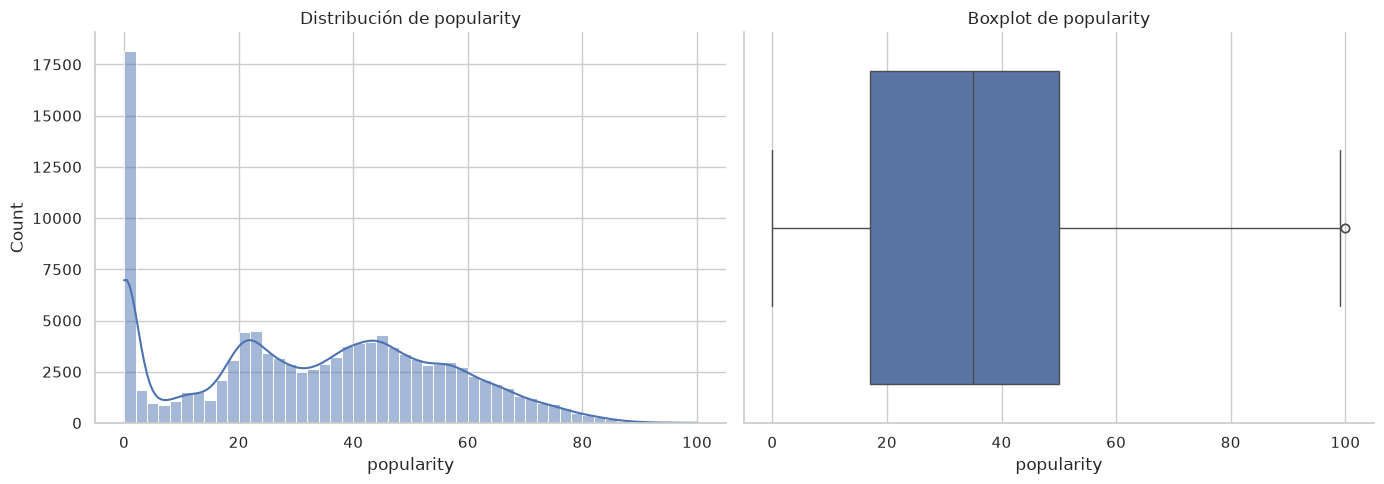

count    114000.000000
mean         33.238535
std          22.305078
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64

Canciones con popularity = 0: 16020 (14.1%)


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['popularity'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribución de popularity')

sns.boxplot(x=df['popularity'], ax=axes[1])
axes[1].set_title('Boxplot de popularity')

plt.tight_layout()
plt.show()

print(df['popularity'].describe())
print(f"\nCanciones con popularity = 0: {(df['popularity'] == 0).sum()} ({(df['popularity'] == 0).mean()*100:.1f}%)")

In [25]:
print(f"Asimetría (skewness) de popularity: {skew(df['popularity']):.3f}")
print(f"Curtosis de popularity: {kurtosis(df['popularity']):.3f}")

Asimetría (skewness) de popularity: 0.046
Curtosis de popularity: -0.928


In [40]:
bins = [-1, 0, 25, 50, 75, 100]
labels = ['Nula (0)', 'Baja (1-25)', 'Media (26-50)', 'Alta (51-75)', 'Muy alta (76-100)']

df['popularity_bucket'] = pd.cut(df['popularity'], bins=bins, labels=labels)

print(df['popularity_bucket'].value_counts().sort_index())
print(f"\nProporción:")
print((df['popularity_bucket'].value_counts(normalize=True).sort_index() * 100).round(1))

popularity_bucket
Nula (0)             16020
Baja (1-25)          28404
Media (26-50)        41806
Alta (51-75)         25356
Muy alta (76-100)     2414
Name: count, dtype: int64

Proporción:
popularity_bucket
Nula (0)             14.1
Baja (1-25)          24.9
Media (26-50)        36.7
Alta (51-75)         22.2
Muy alta (76-100)     2.1
Name: proportion, dtype: float64


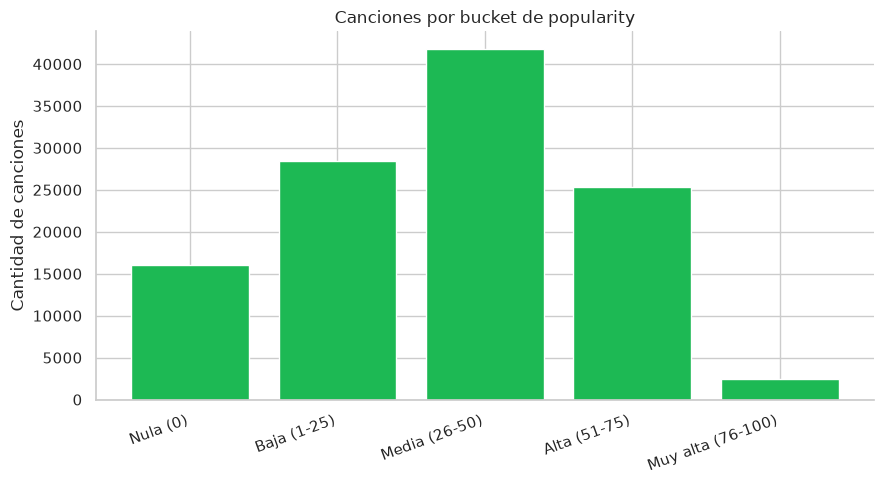

In [41]:
fig, ax = plt.subplots(figsize=(9, 5))
orden_buckets = ['Nula (0)', 'Baja (1-25)', 'Media (26-50)', 'Alta (51-75)', 'Muy alta (76-100)']
conteo = df['popularity_bucket'].value_counts().reindex(orden_buckets)
ax.bar(conteo.index, conteo.values, color='#1DB954')
ax.set_title('Canciones por bucket de popularity')
ax.set_ylabel('Cantidad de canciones')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### Cierre — Fase 3

**Forma de la distribución:** `popularity` no es normal. La asimetría (skewness = 0.046) es prácticamente nula, pero la curtosis (-0.928) es negativa, indicando una distribución platicúrtica — más aplanada que una campana de Gauss, consistente con una forma multimodal (varias jorobas) en vez de un único pico central.

**Concentración en el extremo bajo:** 14.1% de las canciones (16.020) tienen `popularity = 0`, el valor individual más frecuente por lejos.

**Buckets de popularity:** se discretizó la variable en 5 rangos para facilitar comparaciones de grupo en fases siguientes:
- Nula (0): 14.1%
- Baja (1-25): 24.9%
- Media (26-50): 36.7%
- Alta (51-75): 22.2%
- Muy alta (76-100): 2.1%

La distribución confirma que el desafío de este target no es solo su falta de normalidad, sino su naturaleza multimodal — algo a tener en cuenta al elegir métodos de análisis y, más adelante, de modelamiento.

## Fase 4 — Feature engineering exploratorio

Prototipamos variables nuevas a partir de columnas existentes, identificadas como relevantes en las Fases 2 y 3. Aquí solo se construyen y describen — su relación con `popularity` se evalúa recién en la Fase 5.

In [44]:
repeticion_cancion = df.groupby(['track_name', 'artists'])['track_id'].transform('nunique')
df['n_versiones'] = repeticion_cancion

print(df['n_versiones'].describe())
print(f"\nCanciones con 1 sola versión: {(df['n_versiones'] == 1).sum()}")
print(f"Canciones con más de 1 versión: {(df['n_versiones'] > 1).sum()}")

count    113999.000000
mean          1.819595
std           3.322736
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          45.000000
Name: n_versiones, dtype: float64

Canciones con 1 sola versión: 92554
Canciones con más de 1 versión: 21445


In [45]:
df['n_canciones_artista'] = df.groupby('artists')['artists'].transform('count')

print(df['n_canciones_artista'].describe())
print(f"\nTop 10 artistas con más canciones en el dataset:")
print(df.groupby('artists')['n_canciones_artista'].first().sort_values(ascending=False).head(10))

count    113999.000000
mean         24.927157
std          41.590488
min           1.000000
25%           2.000000
50%           9.000000
75%          27.000000
max         279.000000
Name: n_canciones_artista, dtype: float64

Top 10 artistas con más canciones en el dataset:
artists
The Beatles        279.0
George Jones       271.0
Stevie Wonder      236.0
Linkin Park        224.0
Ella Fitzgerald    222.0
Prateek Kuhad      217.0
Feid               202.0
Chuck Berry        190.0
Håkan Hellström    183.0
OneRepublic        181.0
Name: n_canciones_artista, dtype: float64


In [46]:
df['duration_min'] = df['duration_ms'] / 60000
df['duracion_atipica'] = (df['duration_ms'] == 0)

print(df['duration_min'].describe())
print(f"\nCanciones con duración atípica (0 ms): {df['duracion_atipica'].sum()}")

count    114000.000000
mean          3.800486
std           1.788295
min           0.000000
25%           2.901100
50%           3.548433
75%           4.358433
max          87.288250
Name: duration_min, dtype: float64

Canciones con duración atípica (0 ms): 1


In [47]:
df['tempo_valido'] = ~(df['tempo'] == 0)
df['time_signature_valido'] = df['time_signature'].isin([3, 4, 5, 6, 7])

print(f"tempo marcado como faltante: {(~df['tempo_valido']).sum()}")
print(f"time_signature marcado como faltante: {(~df['time_signature_valido']).sum()}")

tempo marcado como faltante: 157
time_signature marcado como faltante: 1136


In [50]:
def contar_artistas(valor):
    if pd.isna(valor):
        return np.nan
    return len(str(valor).split(';'))

df['n_artistas'] = df['artists'].apply(contar_artistas)
df['es_colaboracion'] = df['n_artistas'] > 1

print(df['n_artistas'].describe())
print(f"\nCanciones en colaboración (2+ artistas): {df['es_colaboracion'].sum()} ({df['es_colaboracion'].mean()*100:.1f}%)")
print(f"\nDistribución de cantidad de artistas por canción:")
print(df['n_artistas'].value_counts().sort_index().head(10))

count    113999.000000
mean          1.388538
std           0.863545
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max          38.000000
Name: n_artistas, dtype: float64

Canciones en colaboración (2+ artistas): 30075 (26.4%)

Distribución de cantidad de artistas por canción:
n_artistas
1.0     83924
2.0     21112
3.0      6246
4.0      1706
5.0       512
6.0       221
7.0       118
8.0        51
9.0        24
10.0       24
Name: count, dtype: int64


In [51]:
mapa_macro_genero = {
    # Pop / mainstream
    'pop': 'pop-mainstream', 'pop-film': 'pop-mainstream', 'k-pop': 'pop-mainstream',
    'j-pop': 'pop-mainstream', 'mandopop': 'pop-mainstream', 'cantopop': 'pop-mainstream',
    'indie-pop': 'pop-mainstream', 'synth-pop': 'pop-mainstream', 'power-pop': 'pop-mainstream',
    'j-idol': 'pop-mainstream',

    # Electrónica / dance
    'edm': 'electronica', 'house': 'electronica', 'deep-house': 'electronica',
    'progressive-house': 'electronica', 'chicago-house': 'electronica', 'detroit-techno': 'electronica',
    'techno': 'electronica', 'trance': 'electronica', 'dubstep': 'electronica', 'garage': 'electronica',
    'drum-and-bass': 'electronica', 'electro': 'electronica', 'minimal-techno': 'electronica',
    'club': 'electronica', 'dance': 'electronica', 'breakbeat': 'electronica', 'hardstyle': 'electronica',
    'trip-hop': 'electronica', 'idm': 'electronica', 'electronic': 'electronica', 'dub': 'electronica',

    # Rock / metal
    'rock': 'rock-metal', 'alt-rock': 'rock-metal', 'hard-rock': 'rock-metal', 'punk-rock': 'rock-metal',
    'psych-rock': 'rock-metal', 'indie': 'rock-metal', 'grunge': 'rock-metal', 'metal': 'rock-metal',
    'metalcore': 'rock-metal', 'death-metal': 'rock-metal', 'heavy-metal': 'rock-metal',
    'black-metal': 'rock-metal', 'punk': 'rock-metal', 'rock-n-roll': 'rock-metal', 'goth': 'rock-metal',
    'industrial': 'rock-metal', 'hardcore': 'rock-metal', 'emo': 'rock-metal', 'ska': 'rock-metal',
    'rockabilly': 'rock-metal', 'grindcore': 'rock-metal', 'j-rock': 'rock-metal', 'british': 'rock-metal',

    # Urbano / hip-hop
    'hip-hop': 'urbano', 'reggaeton': 'urbano', 'r-n-b': 'urbano', 'trap': 'urbano',
    'dancehall': 'urbano', 'reggae': 'urbano', 'afrobeat': 'urbano',

    # Clásica / instrumental
    'classical': 'clasica-instrumental', 'opera': 'clasica-instrumental', 'piano': 'clasica-instrumental',
    'acoustic': 'clasica-instrumental', 'ambient': 'clasica-instrumental', 'new-age': 'clasica-instrumental',
    'sleep': 'clasica-instrumental', 'study': 'clasica-instrumental', 'guitar': 'clasica-instrumental',

    # World / regional
    'latin': 'world-regional', 'latino': 'world-regional', 'salsa': 'world-regional', 'samba': 'world-regional',
    'tango': 'world-regional', 'brazil': 'world-regional', 'sertanejo': 'world-regional',
    'pagode': 'world-regional', 'forro': 'world-regional', 'spanish': 'world-regional',
    'turkish': 'world-regional', 'indian': 'world-regional', 'iranian': 'world-regional',
    'malay': 'world-regional', 'french': 'world-regional', 'german': 'world-regional',
    'swedish': 'world-regional', 'world-music': 'world-regional', 'j-dance': 'world-regional',
    'anime': 'world-regional', 'disney': 'world-regional',

    # Folk / singer-songwriter
    'folk': 'folk-singer', 'singer-songwriter': 'folk-singer', 'songwriter': 'folk-singer',
    'country': 'folk-singer', 'honky-tonk': 'folk-singer', 'bluegrass': 'folk-singer', 'gospel': 'folk-singer',
    'blues': 'folk-singer',

    # Jazz / soul / funk
    'jazz': 'jazz-soul-funk', 'soul': 'jazz-soul-funk', 'funk': 'jazz-soul-funk', 'groove': 'jazz-soul-funk',
    'disco': 'jazz-soul-funk',

    # Otros / nicho
    'comedy': 'otros', 'children': 'otros', 'kids': 'otros', 'show-tunes': 'otros',
    'happy': 'otros', 'sad': 'otros', 'chill': 'otros', 'party': 'otros', 'romance': 'otros',
}

df['macro_genero'] = df['track_genre'].map(mapa_macro_genero).fillna('otros')

print(df['macro_genero'].value_counts())
print(f"\nGéneros originales sin mapear (cayeron en 'otros' por defecto): "
      f"{df[~df['track_genre'].isin(mapa_macro_genero.keys())]['track_genre'].nunique()}")

macro_genero
rock-metal              23000
world-regional          21000
electronica             21000
otros                   11000
pop-mainstream          10000
clasica-instrumental     9000
folk-singer              8000
urbano                   6000
jazz-soul-funk           5000
Name: count, dtype: int64

Géneros originales sin mapear (cayeron en 'otros' por defecto): 2


In [52]:
generos_sin_mapear = df[~df['track_genre'].isin(mapa_macro_genero.keys())]['track_genre'].unique()
print(generos_sin_mapear)

<StringArray>
['alternative', 'mpb']
Length: 2, dtype: str


In [53]:
mapa_macro_genero['alternative'] = 'rock-metal'
mapa_macro_genero['mpb'] = 'world-regional'

df['macro_genero'] = df['track_genre'].map(mapa_macro_genero).fillna('otros')

print(df['macro_genero'].value_counts())
print(f"\nGéneros originales sin mapear ahora: "
      f"{df[~df['track_genre'].isin(mapa_macro_genero.keys())]['track_genre'].nunique()}")

macro_genero
rock-metal              24000
world-regional          22000
electronica             21000
pop-mainstream          10000
clasica-instrumental     9000
otros                    9000
folk-singer              8000
urbano                   6000
jazz-soul-funk           5000
Name: count, dtype: int64

Géneros originales sin mapear ahora: 0


### Cierre — Fase 4

Se construyeron 8 variables nuevas a partir de columnas existentes:

**Repetición y catálogo:**
- `n_versiones`: veces que se repite una canción (track_name + artists). Mediana 1, máximo 45.
- `n_canciones_artista`: presencia del artista en el dataset. Mediana 9, máximo 279 (The Beatles).

**Colaboraciones:**
- `n_artistas`: cantidad de artistas en la canción. 26.4% son colaboraciones (2+ artistas), con cola larga hasta 38.
- `es_colaboracion`: bandera binaria derivada de la anterior.

**Duración:**
- `duration_min`: duración en minutos.
- `duracion_atipica`: bandera para el único caso de duración 0.

**Calidad de detección de audio:**
- `tempo_valido` / `time_signature_valido`: banderas para los 157 y 1.136 casos de detección fallida identificados en la Fase 2.

**Género agrupado:**
- `macro_genero`: 114 géneros originales agrupados en 9 macro-categorías (rock-metal, world-regional, electronica, pop-mainstream, clasica-instrumental, otros, folk-singer, urbano, jazz-soul-funk), mapeo validado sin categorías huérfanas.

Ninguna de estas variables ha sido evaluada aún contra `popularity` — esa evaluación es el contenido íntegro de la Fase 5.

## Fase 5 — Búsqueda de señal

Revisión sistemática de todas las variables candidatas (originales y las construidas en la Fase 4) contra `popularity`, usando el método estadístico apropiado según el tipo de cada variable. El objetivo es agotar las vías de búsqueda antes de concluir si existe o no relación real.

In [24]:
pop_cero = df[df['popularity'] == 0]

print("Géneros más comunes entre canciones con popularity = 0:")
print(pop_cero['track_genre'].value_counts().head(10))

print(f"\nProporción de popularity=0 dentro de cada uno de esos géneros:")
for genero in pop_cero['track_genre'].value_counts().head(10).index:
    total_genero = (df['track_genre'] == genero).sum()
    cero_genero = (pop_cero['track_genre'] == genero).sum()
    print(f"  {genero}: {cero_genero}/{total_genero} ({cero_genero/total_genero*100:.1f}%)")

Géneros más comunes entre canciones con popularity = 0:
track_genre
jazz           681
iranian        656
romance        636
soul           611
latin          588
country        587
rock           525
dance          490
alternative    485
house          403
Name: count, dtype: int64

Proporción de popularity=0 dentro de cada uno de esos géneros:
  jazz: 681/1000 (68.1%)
  iranian: 656/1000 (65.6%)
  romance: 636/1000 (63.6%)
  soul: 611/1000 (61.1%)
  latin: 588/1000 (58.8%)
  country: 587/1000 (58.7%)
  rock: 525/1000 (52.5%)
  dance: 490/1000 (49.0%)
  alternative: 485/1000 (48.5%)
  house: 403/1000 (40.3%)


In [26]:
pop_por_genero = df.groupby('track_genre')['popularity'].agg(['mean', 'median', 'std', 'count']).sort_values('mean', ascending=False)

print("Top 10 géneros con MAYOR popularity promedio:")
print(pop_por_genero.head(10))

print("\nTop 10 géneros con MENOR popularity promedio:")
print(pop_por_genero.tail(10))

Top 10 géneros con MAYOR popularity promedio:
               mean  median        std  count
track_genre                                  
pop-film     59.283    60.0  10.249388   1000
k-pop        56.896    60.0  16.946456   1000
chill        53.651    57.0  14.951279   1000
sad          52.379    54.0  11.492756   1000
grunge       49.594    55.0  18.488726   1000
indian       49.539    49.0  11.346595   1000
anime        48.772    50.0  11.811330   1000
emo          48.128    51.0  17.586839   1000
sertanejo    47.866    47.0   3.943551   1000
pop          47.576    66.0  34.040461   1000

Top 10 géneros con MENOR popularity promedio:
                  mean  median        std  count
track_genre                                     
idm             15.766    12.0  10.271258   1000
kids            14.888    12.0   9.240283   1000
grindcore       14.625    14.0   4.499847   1000
jazz            13.628     0.0  23.182905   1000
classical       13.055     3.0  18.093296   1000
chicago-hous

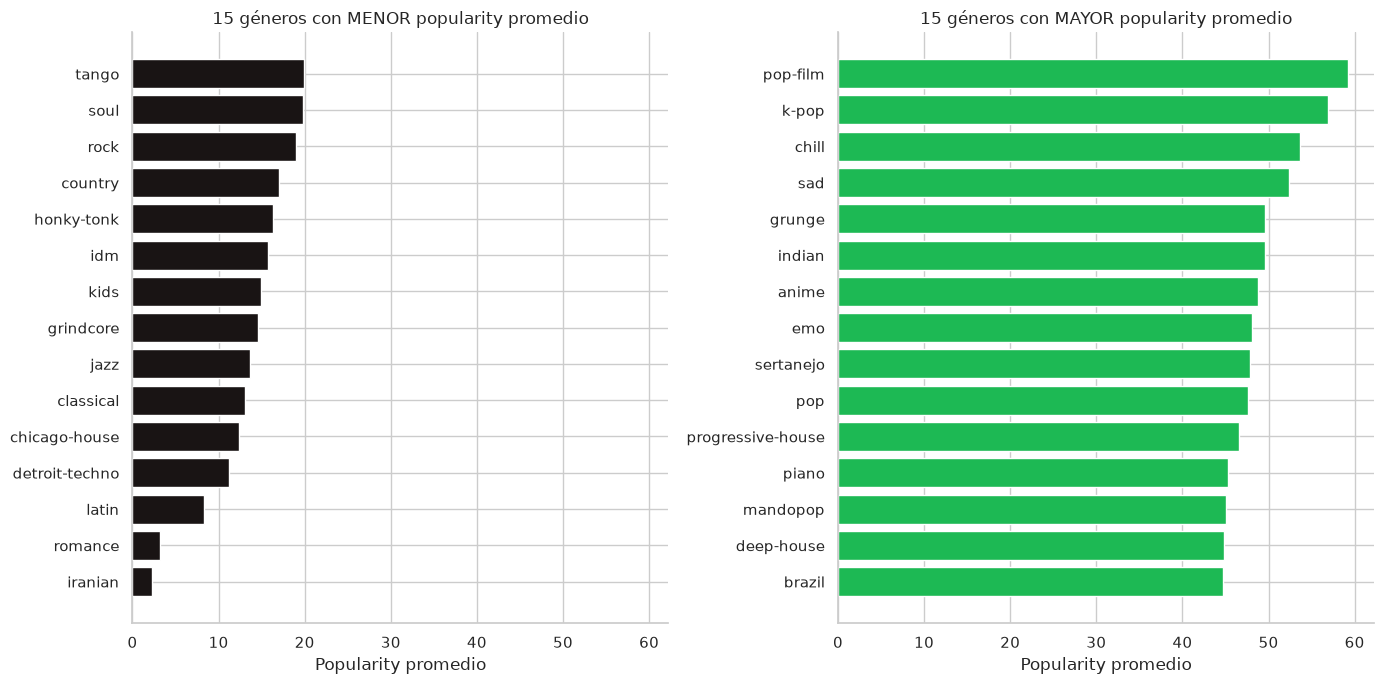

In [38]:
top15 = pop_por_genero.head(15).sort_values('mean')
bottom15 = pop_por_genero.tail(15).sort_values('mean')

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)

axes[0].barh(bottom15.index, bottom15['mean'], color=SPOTIFY_BLACK)
axes[0].set_title('15 géneros con MENOR popularity promedio')
axes[0].set_xlabel('Popularity promedio')

axes[1].barh(top15.index, top15['mean'], color=SPOTIFY_GREEN)
axes[1].set_title('15 géneros con MAYOR popularity promedio')
axes[1].set_xlabel('Popularity promedio')

plt.tight_layout()
plt.show()

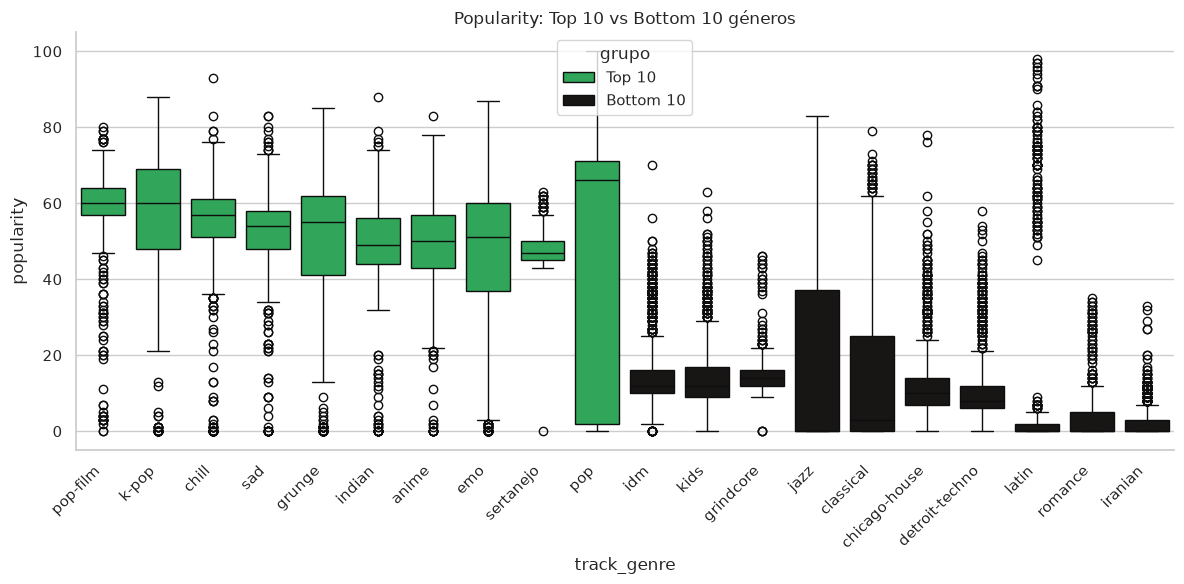

In [39]:
df_comparacion['grupo'] = df_comparacion['track_genre'].apply(lambda g: 'Top 10' if g in top10_generos else 'Bottom 10')

fig, ax = plt.subplots(figsize=(12, 6))
orden = top10_generos + bottom10_generos
sns.boxplot(data=df_comparacion, x='track_genre', y='popularity', hue='grupo', order=orden, ax=ax, dodge=False,
            palette={'Top 10': SPOTIFY_GREEN, 'Bottom 10': SPOTIFY_BLACK})
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_title('Popularity: Top 10 vs Bottom 10 géneros')
plt.tight_layout()
plt.show()

In [33]:
grupos_por_genero = [df[df['track_genre'] == g]['popularity'].values for g in df['track_genre'].unique()]

stat, p_valor = kruskal(*grupos_por_genero)
print(f"Kruskal-Wallis H = {stat:.2f}")
print(f"p-valor = {p_valor:.2e}")
print(f"\n¿Diferencia significativa entre géneros (α=0.05)? {'Sí' if p_valor < 0.05 else 'No'}")

Kruskal-Wallis H = 31281.56
p-valor = 0.00e+00

¿Diferencia significativa entre géneros (α=0.05)? Sí


In [34]:
# Eta-cuadrado aproximado a partir de H de Kruskal-Wallis
n = len(df)
k = df['track_genre'].nunique()
eta_cuadrado = (stat - k + 1) / (n - k)

print(f"Eta-cuadrado aproximado: {eta_cuadrado:.4f}")
print(f"Esto significa que track_genre explica aproximadamente {eta_cuadrado*100:.2f}% de la varianza de popularity")

Eta-cuadrado aproximado: 0.2737
Esto significa que track_genre explica aproximadamente 27.37% de la varianza de popularity


In [42]:
print(df.groupby('explicit')['popularity'].agg(['mean', 'median', 'std', 'count']))

from scipy.stats import mannwhitneyu
grupo_explicit = df[df['explicit'] == True]['popularity']
grupo_no_explicit = df[df['explicit'] == False]['popularity']

stat, p = mannwhitneyu(grupo_explicit, grupo_no_explicit)
print(f"\nMann-Whitney U p-valor: {p:.2e}")
print(f"¿Diferencia significativa (α=0.05)? {'Sí' if p < 0.05 else 'No'}")

               mean  median        std   count
explicit                                      
False     32.937891    34.0  22.083771  104253
True      36.454191    37.0  24.317510    9747

Mann-Whitney U p-valor: 6.14e-42
¿Diferencia significativa (α=0.05)? Sí


In [43]:
print(df.groupby('mode')['popularity'].agg(['mean', 'median', 'std', 'count']))

grupo_mayor = df[df['mode'] == 1]['popularity']
grupo_menor = df[df['mode'] == 0]['popularity']

stat, p = mannwhitneyu(grupo_mayor, grupo_menor)
print(f"\nMann-Whitney U p-valor: {p:.2e}")
print(f"¿Diferencia significativa (α=0.05)? {'Sí' if p < 0.05 else 'No'}")

           mean  median        std  count
mode                                     
0     33.650645    35.0  22.666964  41319
1     33.004251    34.0  22.093435  72681

Mann-Whitney U p-valor: 9.77e-07
¿Diferencia significativa (α=0.05)? Sí


In [54]:
audio_cols = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
              'instrumentalness', 'liveness', 'valence', 'tempo']

correlaciones = pd.DataFrame({
    'pearson': [df[col].corr(df['popularity'], method='pearson') for col in audio_cols],
    'spearman': [df[col].corr(df['popularity'], method='spearman') for col in audio_cols],
}, index=audio_cols)

correlaciones['diferencia_abs'] = (correlaciones['pearson'] - correlaciones['spearman']).abs()
correlaciones = correlaciones.sort_values('diferencia_abs', ascending=False)

correlaciones

,pearson,spearman,diferencia_abs
acousticness,-0.025472,0.008399,0.033872
energy,0.001056,-0.023513,0.024569
speechiness,-0.044927,-0.067872,0.022946
instrumentalness,-0.095139,-0.078454,0.016686
loudness,0.050423,0.035178,0.015245
danceability,0.035448,0.026628,0.008820
tempo,0.013205,0.017085,0.003881
liveness,-0.005387,-0.008189,0.002802
valence,-0.040534,-0.041902,0.001367


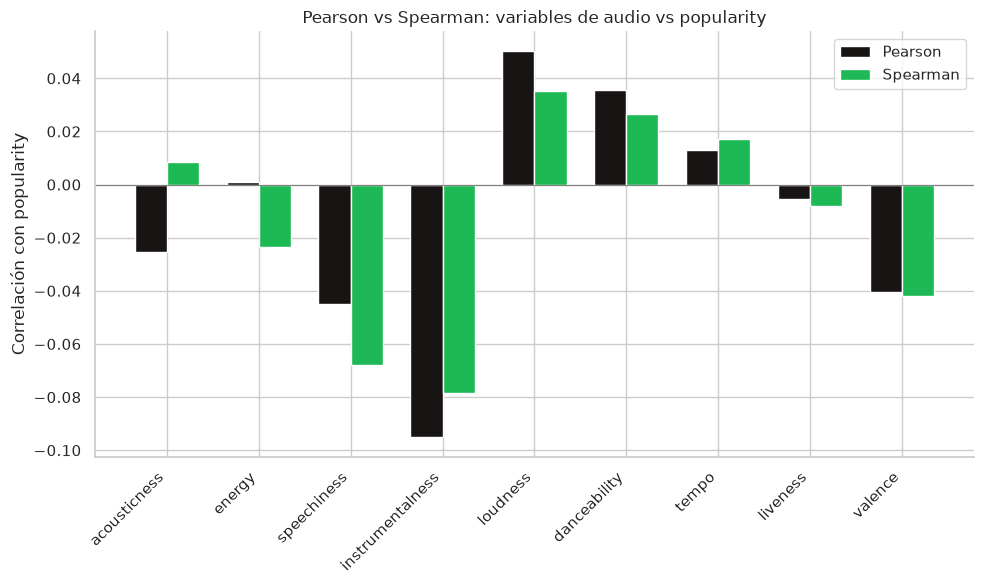

In [55]:
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(correlaciones))
width = 0.35

ax.bar(x - width/2, correlaciones['pearson'], width, label='Pearson', color='#191414')
ax.bar(x + width/2, correlaciones['spearman'], width, label='Spearman', color='#1DB954')

ax.set_xticks(x)
ax.set_xticklabels(correlaciones.index, rotation=45, ha='right')
ax.set_ylabel('Correlación con popularity')
ax.set_title('Pearson vs Spearman: variables de audio vs popularity')
ax.axhline(0, color='gray', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()

In [62]:
p10_bajo = df['popularity'].quantile(0.10)
p90_alto = df['popularity'].quantile(0.90)

grupo_bajo = df[df['popularity'] <= p10_bajo]
grupo_alto = df[df['popularity'] >= p90_alto]

print(f"Umbral bajo (percentil 10): popularity <= {p10_bajo}")
print(f"Umbral alto (percentil 90): popularity >= {p90_alto}")
print(f"Canciones en grupo bajo: {len(grupo_bajo)}")
print(f"Canciones en grupo alto: {len(grupo_alto)}")

resultados_extremos = []
for col in audio_cols:
    media_bajo = grupo_bajo[col].mean()
    media_alto = grupo_alto[col].mean()
    stat, p = mannwhitneyu(grupo_bajo[col], grupo_alto[col])
    resultados_extremos.append({
        'variable': col,
        'media_grupo_bajo': media_bajo,
        'media_grupo_alto': media_alto,
        'diferencia': media_alto - media_bajo,
        'p_valor': p,
        'significativo': p < 0.05
    })

tabla_extremos = pd.DataFrame(resultados_extremos).sort_values('diferencia', key=abs, ascending=False)
tabla_extremos

Umbral bajo (percentil 10): popularity <= 0.0
Umbral alto (percentil 90): popularity >= 63.0
Canciones en grupo bajo: 16020
Canciones en grupo alto: 11435


,variable,media_grupo_bajo,media_grupo_alto,diferencia,p_valor,significativo
8,tempo,118.874871,120.876257,2.001386,6.209422e-09,True
2,loudness,-8.216588,-7.186974,1.029614,1.261116e-41,True
4,acousticness,0.340523,0.255094,-0.085429,2.993847e-69,True
5,instrumentalness,0.102615,0.056574,-0.046040,7.559707e-04,True
1,energy,0.614878,0.654610,0.039732,4.363482e-20,True
0,danceability,0.573724,0.601405,0.027680,3.449020e-27,True
7,valence,0.506835,0.492028,-0.014807,1.596439e-07,True
6,liveness,0.186815,0.178069,-0.008746,1.310122e-02,True
3,speechiness,0.073929,0.076512,0.002583,8.562367e-02,False


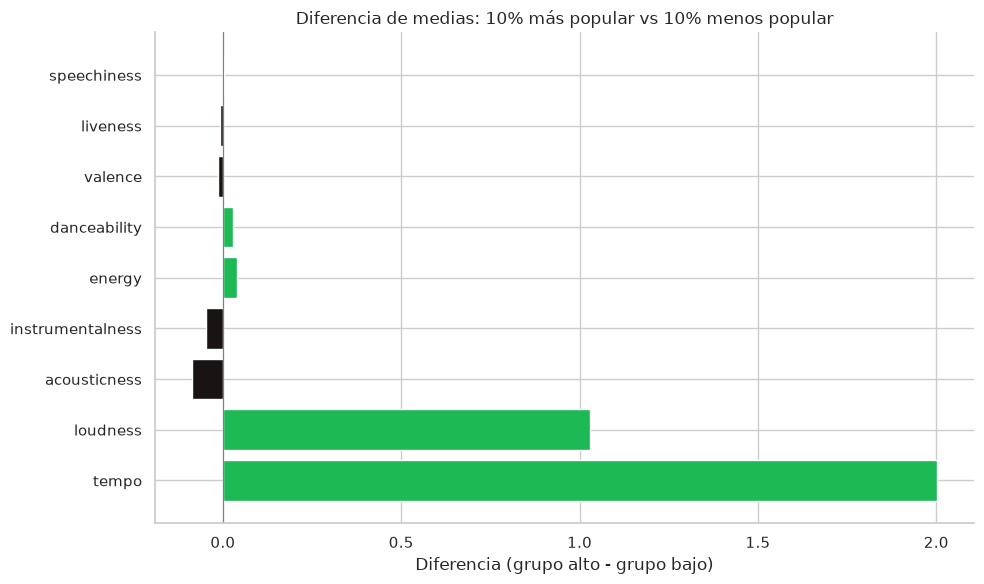

In [63]:
fig, ax = plt.subplots(figsize=(10, 6))
colores = ['#1DB954' if d > 0 else '#191414' for d in tabla_extremos['diferencia']]
ax.barh(tabla_extremos['variable'], tabla_extremos['diferencia'], color=colores)
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_xlabel('Diferencia (grupo alto - grupo bajo)')
ax.set_title('Diferencia de medias: 10% más popular vs 10% menos popular')
plt.tight_layout()
plt.show()

In [64]:
def cohens_d(grupo1, grupo2):
    n1, n2 = len(grupo1), len(grupo2)
    var1, var2 = grupo1.var(ddof=1), grupo2.var(ddof=1)
    pooled_std = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    return (grupo2.mean() - grupo1.mean()) / pooled_std

resultados_normalizados = []
for col in audio_cols:
    d = cohens_d(grupo_bajo[col], grupo_alto[col])
    resultados_normalizados.append({'variable': col, 'cohens_d': d, 'abs_d': abs(d)})

tabla_normalizada = pd.DataFrame(resultados_normalizados).sort_values('abs_d', ascending=False)
tabla_normalizada

,variable,cohens_d,abs_d
4,acousticness,-0.264119,0.264119
2,loudness,0.211066,0.211066
5,instrumentalness,-0.198411,0.198411
1,energy,0.165519,0.165519
0,danceability,0.163347,0.163347
8,tempo,0.068105,0.068105
6,liveness,-0.060487,0.060487
7,valence,-0.059491,0.059491
3,speechiness,0.035208,0.035208


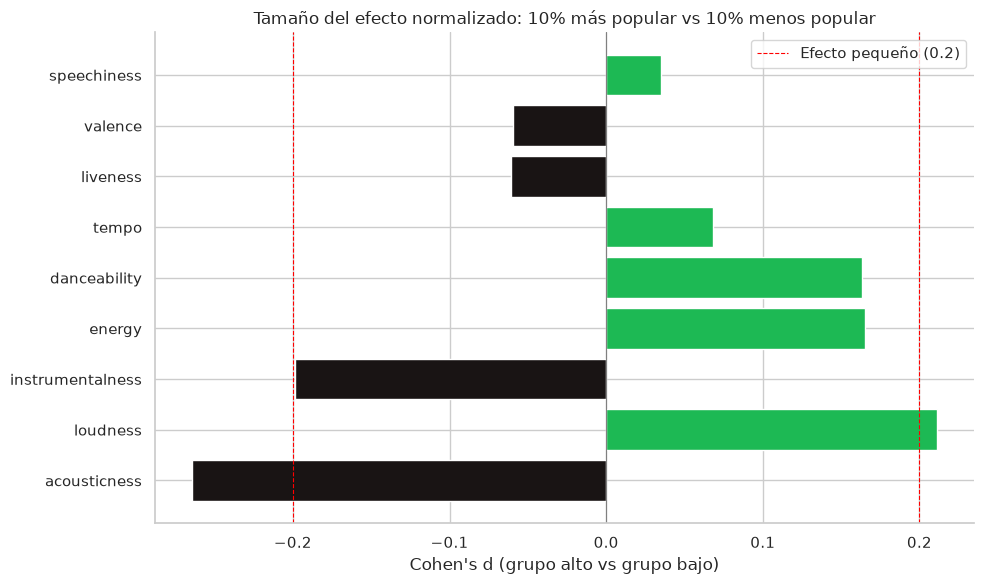

In [65]:
fig, ax = plt.subplots(figsize=(10, 6))
colores = ['#1DB954' if d > 0 else '#191414' for d in tabla_normalizada['cohens_d']]
ax.barh(tabla_normalizada['variable'], tabla_normalizada['cohens_d'], color=colores)
ax.axvline(0, color='gray', linewidth=0.8)
ax.axvline(0.2, color='red', linestyle='--', linewidth=0.8, label='Efecto pequeño (0.2)')
ax.axvline(-0.2, color='red', linestyle='--', linewidth=0.8)
ax.set_xlabel("Cohen's d (grupo alto vs grupo bajo)")
ax.set_title('Tamaño del efecto normalizado: 10% más popular vs 10% menos popular')
ax.legend()
plt.tight_layout()
plt.show()

In [66]:
nuevas_numericas = ['n_versiones', 'n_canciones_artista', 'n_artistas', 'duration_min']

correlaciones_nuevas = pd.DataFrame({
    'pearson': [df[col].corr(df['popularity'], method='pearson') for col in nuevas_numericas],
    'spearman': [df[col].corr(df['popularity'], method='spearman') for col in nuevas_numericas],
}, index=nuevas_numericas)

correlaciones_nuevas

,pearson,spearman
n_versiones,-0.280997,-0.302806
n_canciones_artista,-0.095378,-0.142943
n_artistas,0.006821,0.018733
duration_min,-0.007101,0.028227


In [67]:
print(df.groupby('es_colaboracion')['popularity'].agg(['mean', 'median', 'std', 'count']))

grupo_colab = df[df['es_colaboracion'] == True]['popularity']
grupo_no_colab = df[df['es_colaboracion'] == False]['popularity']
stat, p = mannwhitneyu(grupo_colab, grupo_no_colab)
d = cohens_d(grupo_no_colab, grupo_colab)
print(f"\nMann-Whitney p-valor: {p:.2e} | Cohen's d: {d:.4f}")

                      mean  median        std  count
es_colaboracion                                     
False            33.069193    34.0  21.711569  83925
True             33.711089    38.0  23.877431  30075

Mann-Whitney p-valor: 1.13e-10 | Cohen's d: 0.0288


In [68]:
for col in ['tempo_valido', 'time_signature_valido']:
    print(f"\n--- {col} ---")
    print(df.groupby(col)['popularity'].agg(['mean', 'median', 'std', 'count']))
    g1 = df[df[col] == True]['popularity']
    g2 = df[df[col] == False]['popularity']
    stat, p = mannwhitneyu(g1, g2)
    d = cohens_d(g2, g1)
    print(f"Mann-Whitney p-valor: {p:.2e} | Cohen's d: {d:.4f}")


--- tempo_valido ---
                   mean  median        std   count
tempo_valido                                      
False         37.197452    35.0  11.083853     157
True          33.233075    34.0  22.316197  113843
Mann-Whitney p-valor: 5.54e-02 | Cohen's d: -0.1777

--- time_signature_valido ---
                            mean  median        std   count
time_signature_valido                                      
False                  30.207746    31.0  19.008576    1136
True                   33.269041    35.0  22.333767  112864
Mann-Whitney p-valor: 1.80e-06 | Cohen's d: 0.1373


In [69]:
print(df.groupby('macro_genero')['popularity'].agg(['mean', 'median', 'std', 'count']).sort_values('mean', ascending=False))

grupos_macro = [df[df['macro_genero'] == g]['popularity'].values for g in df['macro_genero'].unique()]
stat_macro, p_macro = kruskal(*grupos_macro)

k_macro = df['macro_genero'].nunique()
eta_macro = (stat_macro - k_macro + 1) / (len(df) - k_macro)

print(f"\nKruskal-Wallis H = {stat_macro:.2f} | p-valor = {p_macro:.2e}")
print(f"Eta-cuadrado: {eta_macro:.4f} ({eta_macro*100:.2f}% de varianza explicada)")

                           mean  median        std  count
macro_genero                                             
pop-mainstream        41.350000    45.0  22.648444  10000
rock-metal            35.008917    34.0  22.756675  24000
world-regional        34.123864    39.0  19.045794  22000
electronica           32.293762    33.0  22.686948  21000
clasica-instrumental  32.154778    32.0  19.296504   9000
folk-singer           30.689750    33.0  23.643945   8000
urbano                29.466667    27.0  26.293931   6000
otros                 28.642444    24.0  19.994719   9000
jazz-soul-funk        27.418400    29.0  26.560746   5000

Kruskal-Wallis H = 2470.31 | p-valor = 0.00e+00
Eta-cuadrado: 0.0216 (2.16% de varianza explicada)


In [70]:
pop_max_por_cancion = df.groupby(['track_name', 'artists']).agg(
    popularity_max=('popularity', 'max'),
    popularity_mean=('popularity', 'mean'),
    n_versiones=('track_id', 'nunique')
).reset_index()

print(pop_max_por_cancion[['popularity_max', 'popularity_mean', 'n_versiones']].describe())

print(f"\nCorrelación n_versiones vs popularity_max: "
      f"{pop_max_por_cancion['n_versiones'].corr(pop_max_por_cancion['popularity_max']):.4f}")
print(f"Correlación n_versiones vs popularity_mean: "
      f"{pop_max_por_cancion['n_versiones'].corr(pop_max_por_cancion['popularity_mean']):.4f}")

       popularity_max  popularity_mean   n_versiones
count    81343.000000     81343.000000  81343.000000
mean        35.249364        34.615436      1.103230
std         19.410056        19.067777      0.730934
min          0.000000         0.000000      1.000000
25%         21.000000        21.000000      1.000000
50%         35.000000        35.000000      1.000000
75%         49.000000        49.000000      1.000000
max        100.000000       100.000000     45.000000

Correlación n_versiones vs popularity_max: 0.0010
Correlación n_versiones vs popularity_mean: -0.1178


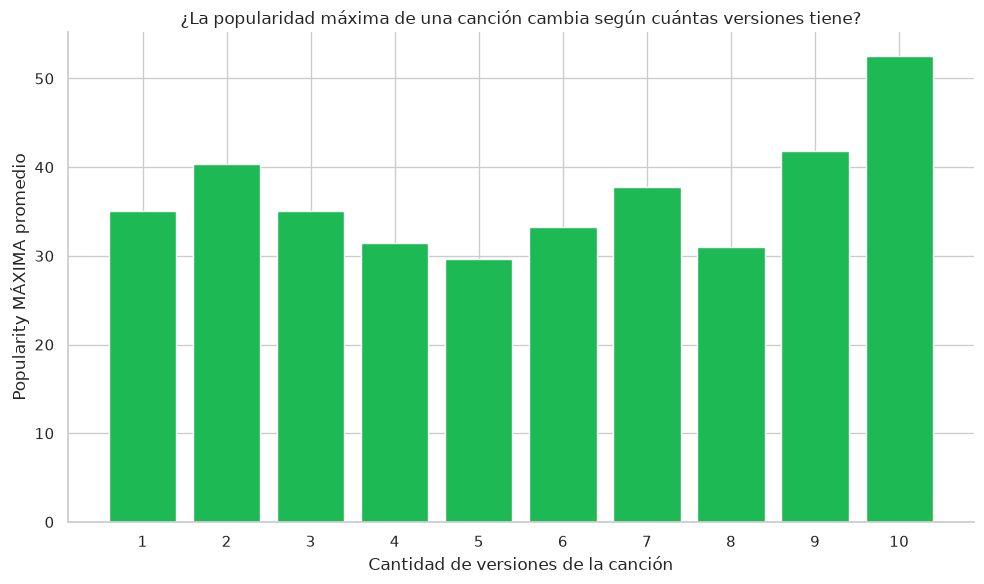

In [71]:
fig, ax = plt.subplots(figsize=(10, 6))
resumen_por_n = pop_max_por_cancion.groupby('n_versiones')['popularity_max'].mean()
resumen_por_n = resumen_por_n[resumen_por_n.index <= 10]  # limitar a n_versiones <=10 por tamaño de muestra
ax.bar(resumen_por_n.index.astype(str), resumen_por_n.values, color='#1DB954')
ax.set_xlabel('Cantidad de versiones de la canción')
ax.set_ylabel('Popularity MÁXIMA promedio')
ax.set_title('¿La popularidad máxima de una canción cambia según cuántas versiones tiene?')
plt.tight_layout()
plt.show()

In [72]:
p1_bajo = df['popularity'].quantile(0.01)
p99_alto = df['popularity'].quantile(0.99)

grupo_bajo_extremo = df[df['popularity'] <= p1_bajo]
grupo_alto_extremo = df[df['popularity'] >= p99_alto]

print(f"Umbral bajo (percentil 1): popularity <= {p1_bajo}")
print(f"Umbral alto (percentil 99): popularity >= {p99_alto}")
print(f"Canciones en grupo bajo extremo: {len(grupo_bajo_extremo)}")
print(f"Canciones en grupo alto extremo: {len(grupo_alto_extremo)}")

resultados_extremo_1_99 = []
for col in audio_cols:
    d = cohens_d(grupo_bajo_extremo[col], grupo_alto_extremo[col])
    stat, p = mannwhitneyu(grupo_bajo_extremo[col], grupo_alto_extremo[col])
    resultados_extremo_1_99.append({'variable': col, 'cohens_d_1_99': d, 'p_valor': p})

tabla_1_99 = pd.DataFrame(resultados_extremo_1_99).sort_values('cohens_d_1_99', key=abs, ascending=False)
tabla_1_99

Umbral bajo (percentil 1): popularity <= 0.0
Umbral alto (percentil 99): popularity >= 80.0
Canciones en grupo bajo extremo: 16020
Canciones en grupo alto extremo: 1201


,variable,cohens_d_1_99,p_valor
4,acousticness,-0.445989,1.364436e-34
0,danceability,0.421140,7.695268e-43
2,loudness,0.402024,5.416810e-43
5,instrumentalness,-0.310242,7.297532e-07
1,energy,0.266978,2.710069e-10
6,liveness,-0.124291,1.497794e-02
3,speechiness,0.098299,2.812976e-02
7,valence,0.026924,5.354182e-01
8,tempo,0.018495,6.484969e-01


In [73]:
comparacion_cortes = tabla_normalizada[['variable', 'cohens_d']].rename(columns={'cohens_d': 'cohens_d_10_90'})
comparacion_cortes = comparacion_cortes.merge(tabla_1_99[['variable', 'cohens_d_1_99']], on='variable')
comparacion_cortes['se_mantiene_o_fortalece'] = comparacion_cortes['cohens_d_1_99'].abs() >= comparacion_cortes['cohens_d_10_90'].abs()
comparacion_cortes.sort_values('cohens_d_10_90', key=abs, ascending=False)

,variable,cohens_d_10_90,cohens_d_1_99,se_mantiene_o_fortalece
0,acousticness,-0.264119,-0.445989,True
1,loudness,0.211066,0.402024,True
2,instrumentalness,-0.198411,-0.310242,True
3,energy,0.165519,0.266978,True
4,danceability,0.163347,0.421140,True
5,tempo,0.068105,0.018495,False
6,liveness,-0.060487,-0.124291,True
7,valence,-0.059491,0.026924,False
8,speechiness,0.035208,0.098299,True


In [74]:
print(df.groupby('key')['popularity'].agg(['mean', 'median', 'std', 'count']).sort_values('mean', ascending=False))

grupos_key = [df[df['key'] == k]['popularity'].values for k in df['key'].unique()]
stat_key, p_key = kruskal(*grupos_key)

k_key = df['key'].nunique()
eta_key = (stat_key - k_key + 1) / (len(df) - k_key)

print(f"\nKruskal-Wallis H = {stat_key:.2f} | p-valor = {p_key:.2e}")
print(f"Eta-cuadrado: {eta_key:.4f} ({eta_key*100:.2f}% de varianza explicada)")

          mean  median        std  count
key                                     
4    34.643650    36.0  21.658282   9008
2    34.377619    36.0  21.148040  11644
11   33.887632    36.0  22.712901   9282
6    33.585532    35.0  22.824662   7921
1    33.200241    34.0  22.837758  10772
3    33.031653    34.0  23.325318   3570
8    32.958696    34.0  23.781247   7360
5    32.930935    34.0  22.820923   9368
9    32.823566    34.0  21.752627  11313
7    32.579615    34.0  21.423258  13245
0    32.519945    33.0  22.183524  13061
10   32.461373    33.0  22.737876   7456

Kruskal-Wallis H = 117.41 | p-valor = 6.02e-20
Eta-cuadrado: 0.0009 (0.09% de varianza explicada)


In [75]:
df_ts_valido = df[df['time_signature_valido']]

print(df_ts_valido.groupby('time_signature')['popularity'].agg(['mean', 'median', 'std', 'count']).sort_values('mean', ascending=False))

grupos_ts = [df_ts_valido[df_ts_valido['time_signature'] == t]['popularity'].values for t in df_ts_valido['time_signature'].unique()]
stat_ts, p_ts = kruskal(*grupos_ts)

k_ts = df_ts_valido['time_signature'].nunique()
eta_ts = (stat_ts - k_ts + 1) / (len(df_ts_valido) - k_ts)

print(f"\nKruskal-Wallis H = {stat_ts:.2f} | p-valor = {p_ts:.2e}")
print(f"Eta-cuadrado: {eta_ts:.4f} ({eta_ts*100:.2f}% de varianza explicada)")

                     mean  median        std   count
time_signature                                      
4               33.672476    35.0  22.378554  101843
3               29.692442    27.0  21.772706    9195
5               28.778204    26.0  20.458514    1826

Kruskal-Wallis H = 364.24 | p-valor = 8.07e-80
Eta-cuadrado: 0.0032 (0.32% de varianza explicada)


In [76]:
df['energy_x_valence'] = df['energy'] * df['valence']
df['danceability_x_energy'] = df['danceability'] * df['energy']
df['acousticness_x_instrumentalness'] = df['acousticness'] * df['instrumentalness']

interacciones = ['energy_x_valence', 'danceability_x_energy', 'acousticness_x_instrumentalness']

tabla_interacciones = pd.DataFrame({
    'pearson': [df[col].corr(df['popularity'], method='pearson') for col in interacciones],
    'spearman': [df[col].corr(df['popularity'], method='spearman') for col in interacciones],
}, index=interacciones)

tabla_interacciones

,pearson,spearman
energy_x_valence,-0.029298,-0.024091
danceability_x_energy,0.006060,-0.002060
acousticness_x_instrumentalness,-0.041292,-0.053569


In [80]:
df['cuadrante_animo'] = np.select(
    [
        (df['energy'] >= 0.5) & (df['valence'] >= 0.5),
        (df['energy'] >= 0.5) & (df['valence'] < 0.5),
        (df['energy'] < 0.5) & (df['valence'] >= 0.5),
        (df['energy'] < 0.5) & (df['valence'] < 0.5),
    ],
    ['Energico-Feliz', 'Energico-Oscuro', 'Calmo-Feliz', 'Calmo-Triste'],
    default='Sin clasificar'
)

print(df.groupby('cuadrante_animo')['popularity'].agg(['mean', 'median', 'std', 'count']).sort_values('mean', ascending=False))

grupos_animo = [df[df['cuadrante_animo'] == c]['popularity'].values for c in df['cuadrante_animo'].unique()]
stat_animo, p_animo = kruskal(*grupos_animo)
k_animo = df['cuadrante_animo'].nunique()
eta_animo = (stat_animo - k_animo + 1) / (len(df) - k_animo)

print(f"\nKruskal-Wallis H = {stat_animo:.2f} | p-valor = {p_animo:.2e}")
print(f"Eta-cuadrado: {eta_animo:.4f} ({eta_animo*100:.2f}% de varianza explicada)")

                      mean  median        std  count
cuadrante_animo                                     
Energico-Oscuro  34.503986    36.0  21.958032  38761
Calmo-Triste     33.722776    37.0  21.932671  23086
Energico-Feliz   32.486949    34.0  22.854286  43405
Calmo-Feliz      30.082762    28.0  21.579787   8748

Kruskal-Wallis H = 380.59 | p-valor = 3.55e-82
Eta-cuadrado: 0.0033 (0.33% de varianza explicada)


In [81]:
resumen_final = pd.DataFrame([
    {'variable': 'track_genre',            'tipo': 'Categórica (114)', 'metodo': 'Kruskal-Wallis',        'resultado': 'eta² = 0.2737', 'senal': 'Fuerte'},
    {'variable': 'acousticness',           'tipo': 'Numérica',        'metodo': 'Cohen\'s d (1%/99%)',    'resultado': 'd = -0.446',    'senal': 'Moderada'},
    {'variable': 'danceability',           'tipo': 'Numérica',        'metodo': 'Cohen\'s d (1%/99%)',    'resultado': 'd = 0.421',     'senal': 'Moderada'},
    {'variable': 'loudness',               'tipo': 'Numérica',        'metodo': 'Cohen\'s d (1%/99%)',    'resultado': 'd = 0.402',     'senal': 'Moderada'},
    {'variable': 'instrumentalness',       'tipo': 'Numérica',        'metodo': 'Cohen\'s d (1%/99%)',    'resultado': 'd = -0.310',    'senal': 'Moderada'},
    {'variable': 'energy',                 'tipo': 'Numérica',        'metodo': 'Cohen\'s d (1%/99%)',    'resultado': 'd = 0.267',     'senal': 'Pequeña-moderada'},
    {'variable': 'explicit',               'tipo': 'Binaria',         'metodo': 'Mann-Whitney',           'resultado': '+3.5 pts prom.','senal': 'Débil (posible confusión con género)'},
    {'variable': 'n_versiones',            'tipo': 'Numérica',        'metodo': 'Pearson/Spearman',       'resultado': 'r = -0.28 (crudo) / 0.001 (con pop. máx.)', 'senal': 'Artefacto de datos, no señal real'},
    {'variable': 'n_canciones_artista',    'tipo': 'Numérica',        'metodo': 'Pearson/Spearman',       'resultado': 'r = -0.10 a -0.14', 'senal': 'Débil, probable mismo artefacto'},
    {'variable': 'time_signature',         'tipo': 'Categórica',      'metodo': 'Kruskal-Wallis',         'resultado': 'eta² = 0.0032',  'senal': 'Trivial'},
    {'variable': 'speechiness',            'tipo': 'Numérica',        'metodo': 'Cohen\'s d',             'resultado': 'd < 0.10',       'senal': 'Trivial'},
    {'variable': 'liveness',               'tipo': 'Numérica',        'metodo': 'Cohen\'s d',             'resultado': 'd < 0.13',       'senal': 'Trivial'},
    {'variable': 'valence',                'tipo': 'Numérica',        'metodo': 'Cohen\'s d (signo inestable)', 'resultado': '-0.06 a +0.03', 'senal': 'Nula / inconsistente'},
    {'variable': 'tempo',                  'tipo': 'Numérica',        'metodo': 'Cohen\'s d (signo inestable)', 'resultado': '0.02 a 0.07',   'senal': 'Nula'},
    {'variable': 'key',                    'tipo': 'Categórica (12)', 'metodo': 'Kruskal-Wallis',         'resultado': 'eta² = 0.0009',  'senal': 'Nula'},
    {'variable': 'mode',                   'tipo': 'Binaria',         'metodo': 'Mann-Whitney',           'resultado': '<1 pt de diferencia', 'senal': 'Nula (trivial pese a p<0.05)'},
    {'variable': 'macro_genero',           'tipo': 'Categórica (9)',  'metodo': 'Kruskal-Wallis',         'resultado': 'eta² = 0.0216',  'senal': 'Débil (peor que track_genre original)'},
    {'variable': 'es_colaboracion',        'tipo': 'Binaria',         'metodo': 'Mann-Whitney',           'resultado': 'd = 0.029',      'senal': 'Nula'},
    {'variable': 'energy × valence (y otras interacciones)', 'tipo': 'Numérica derivada', 'metodo': 'Pearson/Spearman/Kruskal-Wallis', 'resultado': 'r < 0.05, eta² = 0.0033', 'senal': 'Nula'},
])

resumen_final

,variable,tipo,metodo,resultado,senal
0,track_genre,Categórica (114),Kruskal-Wallis,eta² = 0.2737,Fuerte
1,acousticness,Numérica,Cohen's d (1%/99%),d = -0.446,Moderada
2,danceability,Numérica,Cohen's d (1%/99%),d = 0.421,Moderada
3,loudness,Numérica,Cohen's d (1%/99%),d = 0.402,Moderada
4,instrumentalness,Numérica,Cohen's d (1%/99%),d = -0.310,Moderada
5,energy,Numérica,Cohen's d (1%/99%),d = 0.267,Pequeña-moderada
6,explicit,Binaria,Mann-Whitney,+3.5 pts prom.,Débil (posible confusión con género)
7,n_versiones,Numérica,Pearson/Spearman,r = -0.28 (crudo) / 0.001 (con pop. máx.),"Artefacto de datos, no señal real"
8,n_canciones_artista,Numérica,Pearson/Spearman,r = -0.10 a -0.14,"Débil, probable mismo artefacto"
9,time_signature,Categórica,Kruskal-Wallis,eta² = 0.0032,Trivial


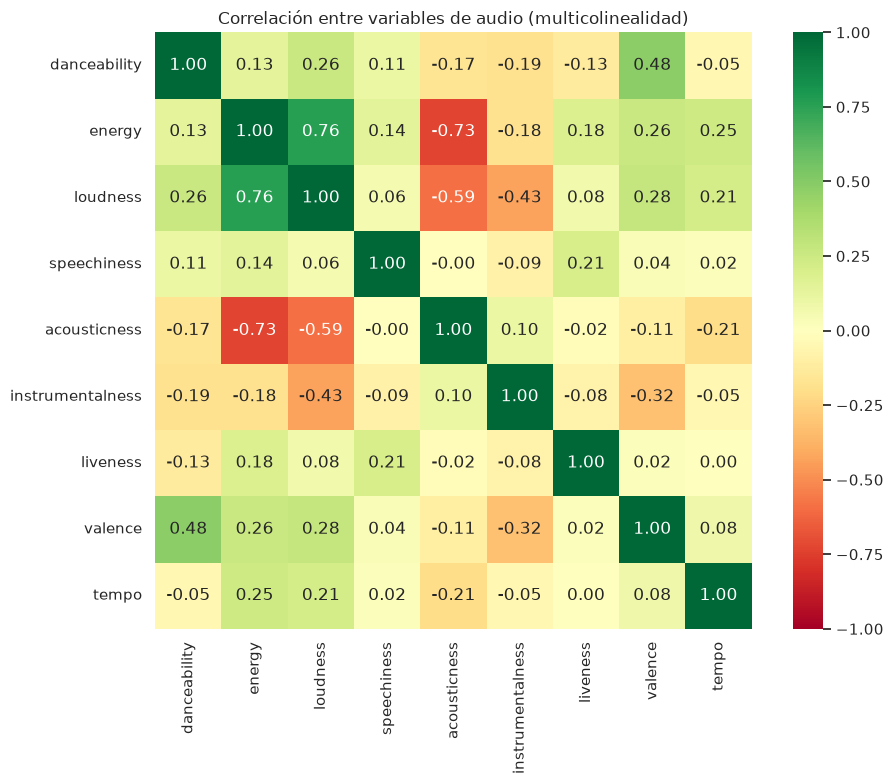

,var_1,var_2,correlacion
0,energy,loudness,0.761690
1,energy,acousticness,-0.733906
2,loudness,acousticness,-0.589803


In [83]:
matriz_corr = df[audio_cols].corr(method='pearson')

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0, 
            vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Correlación entre variables de audio (multicolinealidad)')
plt.tight_layout()
plt.show()

# Marcar pares con correlación fuerte (umbral > 0.5 en valor absoluto)
pares_fuertes = []
for i in range(len(audio_cols)):
    for j in range(i+1, len(audio_cols)):
        corr_val = matriz_corr.iloc[i, j]
        if abs(corr_val) > 0.5:
            pares_fuertes.append({'var_1': audio_cols[i], 'var_2': audio_cols[j], 'correlacion': corr_val})

pd.DataFrame(pares_fuertes).sort_values('correlacion', key=abs, ascending=False) if pares_fuertes else print("Ningún par supera 0.5 de correlación")

### Cierre — Fase 5

Tras una investigación sistemática de 20+ variables (originales, transformadas e interacciones), usando Pearson, Spearman, Cohen's d en múltiples cortes de percentiles, y Kruskal-Wallis con eta², se identifican tres niveles de señal:

**Señal fuerte:**
- `track_genre`: eta² = 0.2737 — explica más varianza que todas las demás variables combinadas.

**Señal moderada (consistente y que se fortalece en cortes más extremos):**
- `acousticness`, `danceability`, `loudness`, `instrumentalness`, `energy` — ninguna es fuerte por sí sola, pero su relación con `popularity` es real y se confirma en múltiples métodos.

**Sin señal práctica (descartadas pese a significancia estadística en varios casos):**
- `tempo`, `valence`, `speechiness`, `liveness`, `key`, `mode`, `time_signature`, interacciones entre variables de audio.

**Hallazgo metodológico destacado:** `n_versiones` mostró inicialmente una correlación aparentemente fuerte (-0.28) que, al investigarse en profundidad, resultó ser un artefacto de cómo el dataset fragmenta la popularidad entre múltiples entradas de una misma canción — no una relación real. Esto valida la importancia de investigar más allá del primer resultado antes de aceptarlo.

**Implicación para el modelamiento futuro:** los atributos de audio, incluso los más prometedores, tienen relación modesta con `popularity`. El género es, por lejos, la variable más informativa disponible en este dataset. Esto sugiere que un modelo robusto probablemente necesite tratar `track_genre` con cuidado (encoding apropiado dada su alta cardinalidad) y que variables externas no presentes en este dataset (artista, fecha de lanzamiento, contexto de plataforma) podrían ser necesarias para mejorar sustancialmente el poder predictivo.

## Fase 6 — Veredicto

Síntesis final: qué aprendimos sobre el problema de negocio, qué variables tienen valor real para el modelamiento, y qué implicaciones tiene esto para la preparación de datos y los pasos siguientes.

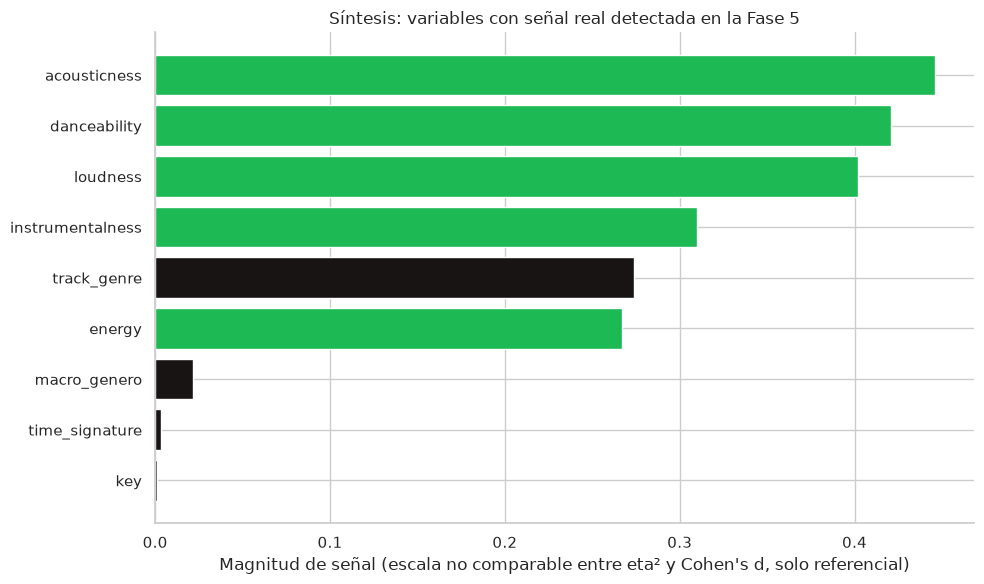

Nota: eta² (negro) y Cohen's d (verde) no son directamente comparables entre sí —
este gráfico solo ordena de forma referencial qué tan lejos está cada variable de 'sin señal'.


In [82]:
señal_resumen = pd.DataFrame([
    {'variable': 'track_genre', 'magnitud': 0.2737, 'tipo_metrica': 'eta²'},
    {'variable': 'acousticness', 'magnitud': 0.446, 'tipo_metrica': "Cohen's d"},
    {'variable': 'danceability', 'magnitud': 0.421, 'tipo_metrica': "Cohen's d"},
    {'variable': 'loudness', 'magnitud': 0.402, 'tipo_metrica': "Cohen's d"},
    {'variable': 'instrumentalness', 'magnitud': 0.310, 'tipo_metrica': "Cohen's d"},
    {'variable': 'energy', 'magnitud': 0.267, 'tipo_metrica': "Cohen's d"},
    {'variable': 'macro_genero', 'magnitud': 0.0216, 'tipo_metrica': 'eta²'},
    {'variable': 'time_signature', 'magnitud': 0.0032, 'tipo_metrica': 'eta²'},
    {'variable': 'key', 'magnitud': 0.0009, 'tipo_metrica': 'eta²'},
]).sort_values('magnitud')

fig, ax = plt.subplots(figsize=(10, 6))
colores = ['#1DB954' if m == "Cohen's d" else '#191414' for m in señal_resumen['tipo_metrica']]
ax.barh(señal_resumen['variable'], señal_resumen['magnitud'], color=colores)
ax.set_xlabel('Magnitud de señal (escala no comparable entre eta² y Cohen\'s d, solo referencial)')
ax.set_title('Síntesis: variables con señal real detectada en la Fase 5')
plt.tight_layout()
plt.show()

print("Nota: eta² (negro) y Cohen's d (verde) no son directamente comparables entre sí —")
print("este gráfico solo ordena de forma referencial qué tan lejos está cada variable de 'sin señal'.")

### Veredicto final del EDA

**Sobre la pregunta de investigación inicial:** planteamos si los atributos de audio por sí solos explican la popularidad de una canción. La respuesta, tras una investigación exhaustiva con múltiples métodos (Pearson, Spearman, comparación de extremos en distintos cortes, Kruskal-Wallis, interacciones), es **no de forma suficiente**. El conjunto de atributos de audio tiene relación real pero modesta (Cohen's d entre 0.27 y 0.45 para las 5 variables más prometedoras), mientras que `track_genre` por sí solo (eta²=0.27) supera ampliamente a cualquier combinación de variables de audio.

**Variables que entran al pipeline de preparación con justificación fuerte:**
- `track_genre` (114 categorías) — la señal más importante del dataset; requiere una estrategia de codificación que no distorsione su cardinalidad (a definir en el pipeline: one-hot, frequency o target encoding).
- `acousticness`, `danceability`, `loudness`, `instrumentalness`, `energy` — señal moderada y consistente en múltiples cortes.
- `explicit` — señal débil pero presente, con la salvedad de que podría estar mediada por género.

**Variables que se descartan como predictoras (pero pueden mantenerse por otras razones, ej. interpretabilidad o registro):**
- `tempo`, `valence`, `speechiness`, `liveness`, `key`, `mode`, `time_signature` — sin señal práctica pese a significancia estadística en varios casos.
- `macro_genero` — pierde la mayor parte de la señal que sí tiene `track_genre` original; no se recomienda como reemplazo.
- `n_versiones`, `n_canciones_artista` — la correlación inicial resultó ser mayormente un artefacto de la estructura del dataset (fragmentación de popularidad entre entradas repetidas), no señal real sobre el éxito de la canción.
- Interacciones entre variables de audio (`energy × valence`, etc.) — no revelaron señal adicional a la de sus componentes individuales.

**Decisiones que se trasladan al pipeline de preparación (`02_Preparacion.ipynb`):**
1. Consolidar canciones duplicadas usando la popularidad **máxima** entre versiones (justificado por el hallazgo de la Fase 5, no por conveniencia arbitraria como en el primer intento).
2. Tratar `tempo=0` y `time_signature` en {0,1} como valores faltantes, no como ceros reales (siguiendo el hallazgo de la Fase 2).
3. Definir la estrategia de codificación de `track_genre` dado su rol central como predictor.
4. Evaluar si `IQR` es más apropiado que percentiles fijos para outliers de `duration_ms`, dado el hallazgo de valores extremos reales (no solo errores) en esa variable.

**Limitación honesta:** incluso con las 5-6 variables de mejor señal identificadas, la capacidad predictiva combinada de este dataset parece limitada. Es probable que un modelo entrenado solo con estas variables tenga desempeño modesto, y que se requieran datos externos (fecha de lanzamiento, presencia en playlists editoriales, indicadores de marketing/promoción) para explicar la popularidad de forma más completa — algo que excede el alcance de este EP1 pero que vale la pena declarar explícitamente como conclusión del EDA.

### Adición al veredicto — Multicolinealidad entre variables de audio

La matriz de correlación entre las variables de audio predictoras muestra tres relaciones fuertes: `energy`-`loudness` (0.76), `energy`-`acousticness` (-0.73) y `loudness`-`acousticness` (-0.59). Estas son precisamente 3 de las 5 variables identificadas con mejor señal en la Fase 5, lo que sugiere que buena parte de su poder predictivo es redundante entre sí (describen una dimensión similar: intensidad/producción de la canción).

**Implicación para el pipeline:** al escalar y preparar los datos para un futuro modelo, se debe tener en cuenta esta multicolinealidad — especialmente relevante si se usa un modelo lineal. Alternativas a evaluar en la fase de modelamiento: mantener las tres variables y aplicar regularización (Ridge/Lasso), o considerar una reducción de dimensionalidad (PCA) sobre este subconjunto correlacionado.